In [2]:
import os, glob, time
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import jax, jax.numpy as jnp
import optax
import pickle

jax.config.update("jax_enable_x64", False)
print(jax.devices())

DATA_ROOT = os.environ.get("DATA_ROOT", os.path.expanduser("~/private/Dsc-180/"))
OUT = "~/private/Dsc-180/output"
TRAIN = ["ssp126", "ssp370", "ssp585", "historical", "hist-GHG", "hist-aer"]
TEST = "ssp245"

N_SO2_PC, N_BC_PC = 5, 5     # input compression
N_TAS_PC = 20                # output patterns
HIDDEN = (64, 64)
STEPS, LR, WD = 3000, 1e-3, 1e-4
SEEDS = [0, 1, 2, 3, 4]
STEPS, LR, WD = 3000, 1e-3, 1e-4
START, END = 2080, 2100      # ClimateBench scoring window

BEST_WEEK3_TAS_TOTAL = 0.284

Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda12.initialize()
Traceback (most recent call last):
  File "/home/vpaidi/climatebench-env/lib/python3.11/site-packages/jax/_src/xla_bridge.py", line 508, in discover_pjrt_plugins
    plugin_module.initialize()
  File "/home/vpaidi/climatebench-env/lib/python3.11/site-packages/jax_plugins/xla_cuda12/__init__.py", line 370, in initialize
    _check_cuda_versions(raise_on_first_error = True)
  File "/home/vpaidi/climatebench-env/lib/python3.11/site-packages/jax_plugins/xla_cuda12/__init__.py", line 274, in _check_cuda_versions
    for d in range(cuda_versions.cuda_device_count())
                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: jaxlib/cuda/versions_helpers.cc:135: operation cuInit(0) failed: Unknown CUDA error 303; cuGetErrorName failed. This probably means that JAX was unable to load the CUDA libraries.


[CpuDevice(id=0)]


In [7]:
def find(name):
    hits = glob.glob(os.path.join(DATA_ROOT, "**", name), recursive=True)
    if not hits:
        raise FileNotFoundError(f"{name} not found under {DATA_ROOT}")
    return hits[0]

def load(scenario):
    """Inputs and ensemble-mean tas for one scenario, on the years both files share."""
    X = xr.open_dataset(find(f"inputs_{scenario}.nc"))
    Y = xr.open_dataset(find(f"outputs_{scenario}.nc"))
    if "member" in Y.dims:
        Y = Y.mean("member")
    years = np.intersect1d(X.time.values, Y.time.values)
    X, Y = X.sel(time=years), Y.sel(time=years)
    return {
        "years": years,
        "co2": X["CO2"].values.astype(np.float32),                        # (T,)
        "ch4": X["CH4"].values.astype(np.float32),                        # (T,)
        "so2": X["SO2"].transpose("time", ...).values.astype(np.float32), # (T, lat, lon)
        "bc":  X["BC"].transpose("time", ...).values.astype(np.float32),  # (T, lat, lon)
        "tas": Y["tas"].transpose("time", ...).values.astype(np.float32), # (T, lat, lon)
        "lat": Y["lat"].values,
        "lon": Y["lon"].values,
    }

data = {}
for s in TRAIN + [TEST]:
    try:
        data[s] = load(s)
        d = data[s]
        print(f"{s:11s} years {d['years'][0]}-{d['years'][-1]} ({len(d['years'])}) | tas {d['tas'].shape}")
    except FileNotFoundError as e:
        print("skipping:", e)
TRAIN = [s for s in TRAIN if s in data]
assert TEST in data, "need the ssp245 test files"

lat, lon = data[TEST]["lat"], data[TEST]["lon"]
NLAT, NLON = len(lat), len(lon)
area_w = np.cos(np.deg2rad(lat))[:, None] * np.ones((1, NLON))
area_w = jnp.asarray(area_w / area_w.mean(), dtype=jnp.float32)      # (lat, lon), mean 1

ssp126      years 2015-2100 (86) | tas (86, 96, 144)
ssp370      years 2015-2100 (86) | tas (86, 96, 144)
ssp585      years 2015-2100 (86) | tas (86, 96, 144)
historical  years 1850-2014 (165) | tas (165, 96, 144)
hist-GHG    years 1850-2014 (165) | tas (165, 96, 144)
hist-aer    years 1850-2014 (165) | tas (165, 96, 144)
ssp245      years 2015-2100 (86) | tas (86, 96, 144)


In [8]:
def stack(key):
    return np.concatenate([data[s][key] for s in TRAIN], axis=0)

def pca(maps, k):
    """Mean map and the first k patterns (k, lat*lon) of a stack of maps."""
    A = maps.reshape(len(maps), -1)
    mean = A.mean(0)
    _, svals, Vt = np.linalg.svd(A - mean, full_matrices=False)
    explained = (svals[:k] ** 2).sum() / (svals ** 2).sum()
    return mean.astype(np.float32), Vt[:k].astype(np.float32), explained

so2_mean, so2_pcs, ev = pca(stack("so2"), N_SO2_PC); print(f"SO2: {N_SO2_PC} PCs explain {ev:.1%}")
bc_mean,  bc_pcs,  ev = pca(stack("bc"),  N_BC_PC);  print(f"BC:  {N_BC_PC} PCs explain {ev:.1%}")
tas_mean, tas_pcs, ev = pca(stack("tas"), N_TAS_PC); print(f"tas: {N_TAS_PC} PCs explain {ev:.1%}")

# everything emulate() needs, as fixed jnp arrays
PRE = {k: jnp.asarray(v) for k, v in dict(so2_mean=so2_mean, so2_pcs=so2_pcs,
                                          bc_mean=bc_mean, bc_pcs=bc_pcs,
                                          tas_mean=tas_mean, tas_pcs=tas_pcs).items()}

C_train = (stack("tas").reshape(-1, NLAT * NLON) - tas_mean) @ tas_pcs.T     # (N, N_TAS_PC)
PRE["c_std"] = jnp.asarray(C_train.std(0) + 1e-8)
print("pattern-weight std (first 5):", np.asarray(PRE["c_std"][:5]).round(1))

def features(co2, ch4, so2, bc, pre=None):
    """(T,), (T,), (T,lat,lon), (T,lat,lon) -> raw features (T, 2 + N_SO2_PC + N_BC_PC)."""
    pre = PRE if pre is None else pre
    T = co2.shape[0]
    so2_f = (so2.reshape(T, -1) - pre["so2_mean"]) @ pre["so2_pcs"].T
    bc_f  = (bc.reshape(T, -1)  - pre["bc_mean"])  @ pre["bc_pcs"].T
    return jnp.concatenate([co2[:, None], ch4[:, None], so2_f, bc_f], axis=1)

# standardization constants from the training features
F_train = np.concatenate([np.asarray(features(*(jnp.asarray(data[s][k]) for k in ["co2", "ch4", "so2", "bc"])))
                          for s in TRAIN])
PRE["f_mean"] = jnp.asarray(F_train.mean(0))
PRE["f_std"] = jnp.asarray(F_train.std(0) + 1e-8)
print("feature matrix:", F_train.shape)

SO2: 5 PCs explain 94.9%
BC:  5 PCs explain 98.1%
tas: 20 PCs explain 96.5%
pattern-weight std (first 5): [159.5  24.7  19.2  16.4  15.9]
feature matrix: (753, 12)


In [9]:
def init_mlp(key, sizes):
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        key, sub = jax.random.split(key)
        params.append({"W": jax.random.normal(sub, (n_in, n_out)) * jnp.sqrt(1.0 / n_in),
                       "b": jnp.zeros(n_out)})
    params.append({"W": jnp.zeros((sizes[0], sizes[-1])), "b": jnp.zeros(sizes[-1])})  # linear shortcut
    return params

def mlp(params, x):
    *layers, skip = params
    h = x
    for layer in layers[:-1]:
        h = jnp.tanh(h @ layer["W"] + layer["b"])
    return h @ layers[-1]["W"] + layers[-1]["b"] + x @ skip["W"] + skip["b"]

def predict(params, co2, ch4, so2, bc, pre=None):
    """One network: inputs -> tas maps (T, lat, lon)."""
    pre = PRE if pre is None else pre
    x = (features(co2, ch4, so2, bc, pre) - pre["f_mean"]) / pre["f_std"]
    coeffs = mlp(params, x) * pre["c_std"]                                   # (T, N_TAS_PC)
    maps = pre["tas_mean"] + coeffs @ pre["tas_pcs"]         # (T, lat*lon)
    return maps.reshape(co2.shape[0], NLAT, NLON)

# training arrays (all training scenarios concatenated along time)
Xtr = {k: jnp.asarray(stack(k)) for k in ["co2", "ch4", "so2", "bc"]}
Ytr = jnp.asarray(stack("tas"))

def loss_fn(params):
    pred = predict(params, Xtr["co2"], Xtr["ch4"], Xtr["so2"], Xtr["bc"])
    return jnp.mean(area_w * (pred - Ytr) ** 2)              # latitude-weighted MSE (K²)

seed 0: final train loss 0.1887 K² (215.8 s)
seed 1: final train loss 0.1895 K² (213.7 s)
seed 2: final train loss 0.1916 K² (214.4 s)
seed 3: final train loss 0.1871 K² (214.4 s)
seed 4: final train loss 0.1914 K² (216.2 s)


Text(0.5, 1.0, 'Training loss')

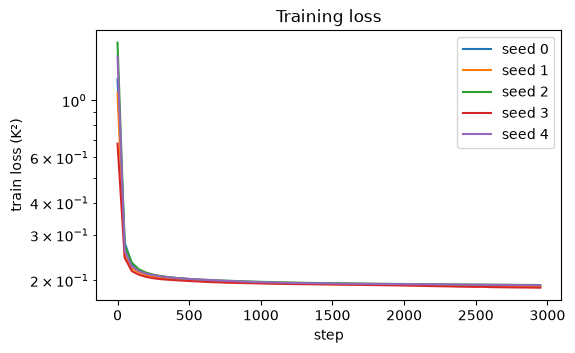

In [10]:
sizes = [int(PRE["f_mean"].shape[0]), *HIDDEN, N_TAS_PC]
opt = optax.adamw(LR, weight_decay=WD)

@jax.jit
def step(params, opt_state):
    loss, grads = jax.value_and_grad(loss_fn)(params)
    updates, opt_state = opt.update(grads, opt_state, params)
    return optax.apply_updates(params, updates), opt_state, loss

trained, histories = [], {}
for seed in SEEDS:
    params = init_mlp(jax.random.key(seed), sizes)
    opt_state = opt.init(params)
    t0, hist = time.time(), []
    for i in range(STEPS):
        params, opt_state, loss = step(params, opt_state)
        if i % 50 == 0:
            hist.append(float(loss))
    trained.append(params)
    histories[seed] = hist
    print(f"seed {seed}: final train loss {float(loss):.4f} K² ({time.time() - t0:.1f} s)")

plt.figure(figsize=(6, 3.5))
for seed, h in histories.items():
    plt.semilogy(np.arange(len(h)) * 50, h, label=f"seed {seed}")
plt.xlabel("step"); plt.ylabel("train loss (K²)"); plt.legend(); plt.title("Training loss")

In [11]:
STACKED = jax.tree_util.tree_map(lambda *p: jnp.stack(p), *trained)   # each leaf: (n_seeds, ...)
PRE_FROZEN = dict(PRE)                                                   # snapshot of the preprocessing

@jax.jit
def emulate(co2, ch4, so2, bc):
    """ClimateBench inputs for one scenario -> tas, shape (years, lat, lon)."""
    per_seed = jax.vmap(lambda p: predict(p, co2, ch4, so2, bc, PRE_FROZEN))(STACKED)
    return per_seed.mean(0)

In [12]:
def gmean(x):                      # x: (..., lat, lon) -> (...)
    return (x * area_w).mean((-2, -1))

def nrmse(truth, pred, years, start=START, end=END):
    sel = (years >= start) & (years <= end)
    t, p = truth[sel], pred[sel]
    norm = abs(float(gmean(t.mean(0))))
    spatial = float(jnp.sqrt(gmean((t.mean(0) - p.mean(0)) ** 2))) / norm
    glob_ = float(jnp.sqrt(jnp.mean((gmean(t) - gmean(p)) ** 2))) / norm
    return {"NRMSE spatial": spatial, "NRMSE global": glob_, "NRMSE total": spatial + 5 * glob_}

d = data[TEST]
pred_245 = emulate(*(jnp.asarray(d[k]) for k in ["co2", "ch4", "so2", "bc"]))
truth_245 = jnp.asarray(d["tas"])

scores = {"NN ensemble": nrmse(truth_245, pred_245, d["years"])}
for seed, p in zip(SEEDS, trained):
    scores[f"seed {seed}"] = nrmse(truth_245, predict(p, *(jnp.asarray(d[k]) for k in ["co2", "ch4", "so2", "bc"])), d["years"])
score_df = pd.DataFrame(scores).T
display(score_df.round(3))

if BEST_WEEK3_TAS_TOTAL:
    ratio = score_df.loc["NN ensemble", "NRMSE total"] / BEST_WEEK3_TAS_TOTAL
    print(f"ensemble / best week 3 = {ratio:.2f}  ->  {'within' if ratio <= 1.2 else 'NOT within'} 20%")

,NRMSE spatial,NRMSE global,NRMSE total
NN ensemble,0.091,0.043,0.305
seed 0,0.091,0.048,0.331
seed 1,0.096,0.045,0.321
seed 2,0.076,0.040,0.277
seed 3,0.220,0.083,0.636
seed 4,0.076,0.041,0.283


ensemble / best week 3 = 1.07  ->  within 20%


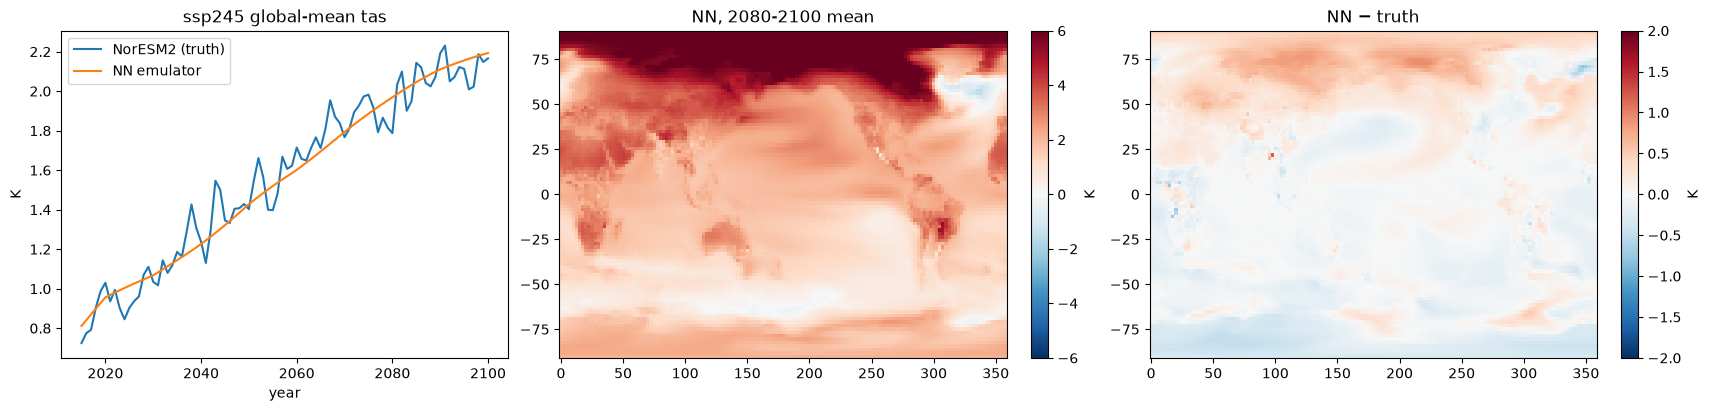

In [13]:
yrs = d["years"]
fig, ax = plt.subplots(1, 3, figsize=(17, 4), constrained_layout=True)
ax[0].plot(yrs, gmean(truth_245), label="NorESM2 (truth)")
ax[0].plot(yrs, gmean(pred_245), label="NN emulator")
ax[0].set(title="ssp245 global-mean tas", xlabel="year", ylabel="K"); ax[0].legend()

sel = (yrs >= START) & (yrs <= END)
t_map, p_map = truth_245[sel].mean(0), pred_245[sel].mean(0)
for a, field, title, cmap, lim in [(ax[1], p_map, "NN, 2080-2100 mean", "RdBu_r", 6),
                                   (ax[2], p_map - t_map, "NN − truth", "RdBu_r", 2)]:
    m = a.pcolormesh(lon, lat, np.asarray(field), cmap=cmap, vmin=-lim, vmax=lim)
    a.set_title(title); plt.colorbar(m, ax=a, label="K")
    

In [14]:
#Gradients of the 2100 global-mean temperature wrt inputs
args = [jnp.asarray(d[k]) for k in ["co2", "ch4", "so2", "bc"]]
J = lambda co2, ch4, so2, bc: gmean(emulate(co2, ch4, so2, bc)[-1])
g_co2, g_ch4, g_so2, g_bc = jax.grad(J, argnums=(0, 1, 2, 3))(*args)
print("dT2100/dCO2 (per unit cumulative CO2, by year), last 5 years:", np.asarray(g_co2[-5:]))
print("dT2100/dSO2 map: shape", g_so2.shape, "| largest |value| in year 2100:", float(jnp.abs(g_so2[-1]).max()))

dT2100/dCO2 (per unit cumulative CO2, by year), last 5 years: [0.         0.         0.         0.         0.00049505]
dT2100/dSO2 map: shape (86, 96, 144) | largest |value| in year 2100: 65268180.0


In [15]:
import os

# Create output dir if it doesn't exist
os.makedirs(OUT, exist_ok=True)

# Also expand ~ in case OUT contains a home-relative path
OUT = os.path.expanduser(OUT)

score_df.to_csv(f"{OUT}/emulator_scores_ssp245.csv")
np.save(f"{OUT}/pred_tas_ssp245.npy", np.asarray(pred_245))

with open(f"{OUT}/emulator.pkl", "wb") as f:
    pickle.dump(jax.device_get({"params": STACKED, "pre": PRE_FROZEN,
                                "nlat": NLAT, "nlon": NLON, "lat": lat, "lon": lon}), f)

In [16]:

score_df.to_csv(f"{OUT}/emulator_scores_ssp245.csv")
np.save(f"{OUT}/pred_tas_ssp245.npy", np.asarray(pred_245))

with open(f"{OUT}/emulator.pkl", "wb") as f:
    pickle.dump(jax.device_get({"params": STACKED, "pre": PRE_FROZEN,
                                "nlat": NLAT, "nlon": NLON, "lat": lat, "lon": lon}), f)

Region mask: 754 grid cells (5.5% of globe)
Scoring window: 2081–2100


E1123 02:06:01.634899    2085 slow_operation_alarm.cc:73] Constant folding an instruction is taking > 1s:

  %scatter-add.5 = f32[86,96,144]{2,1,0} scatter(%broadcast_in_dim.9, %constant.40, %broadcast.5), update_window_dims={1,2}, inserted_window_dims={0}, scatter_dims_to_operand_dims={0}, index_vector_dim=1, to_apply=%region_0.2, metadata={op_name="jit(scalar_J)/transpose(jvp())/scatter-add" stack_frame_id=32}

This isn't necessarily a bug; constant-folding is inherently a trade-off between compilation time and speed at runtime. XLA has some guards that attempt to keep constant folding from taking too long, but fundamentally you'll always be able to come up with an input program that takes a long time.

If you'd like to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
E1123 02:06:01.685494    2082 slow_operation_alarm.cc:140] The operation took 1.050753339s
Constant folding an instruction is taking > 1s:

  %scatter-add.5 = f32[86,96,144]{2,1,0} sc

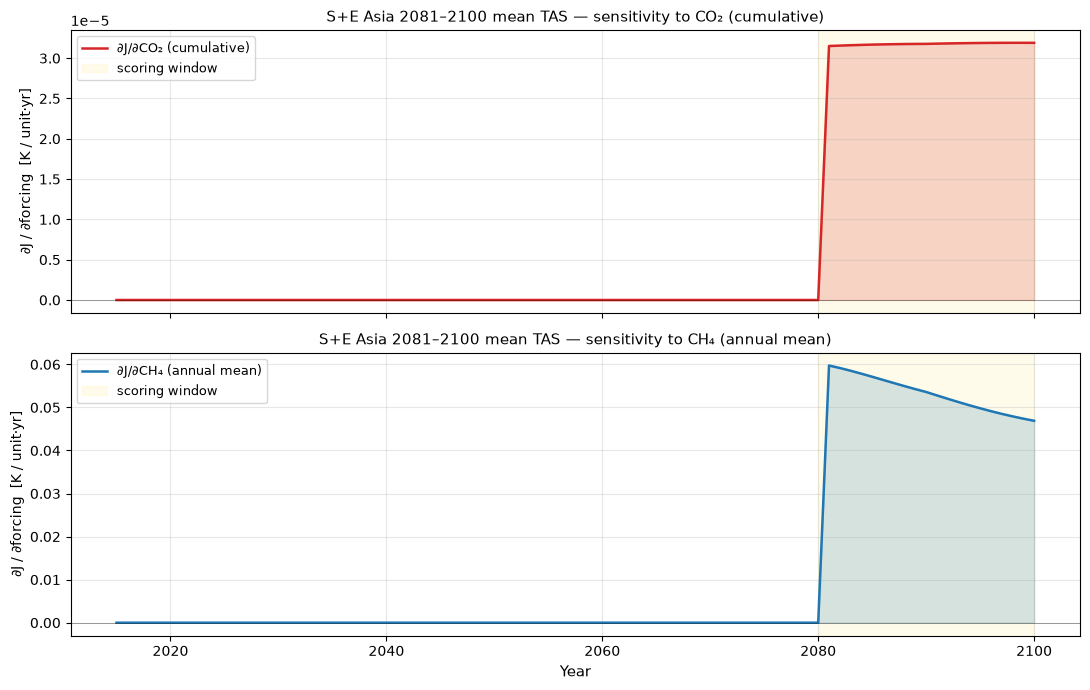

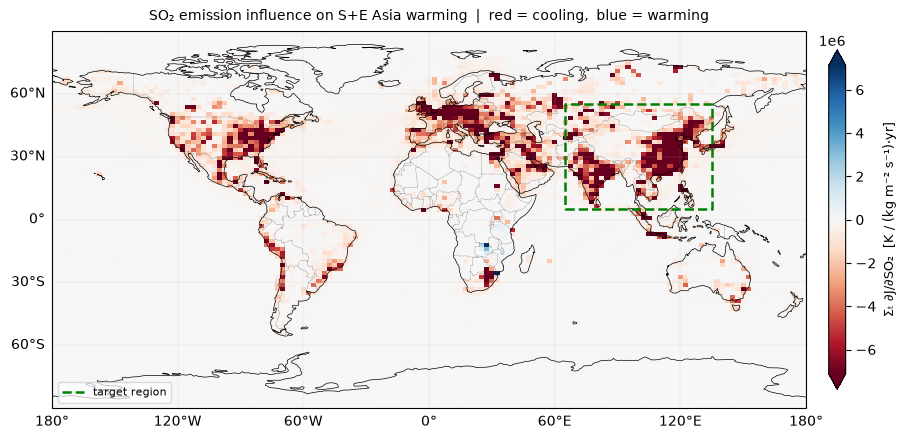

In [17]:
# plotting regional sensitivities to CO2, SO2

import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import TwoSlopeNorm

# South, South east asian region
LAT_MIN, LAT_MAX =  5.0, 55.0   # N covers India through N. China
LON_MIN, LON_MAX = 65.0, 135.0  # E covers Pakistan through E. China

d245      = data[TEST]
lat_245   = d245["lat"]
lon_245   = d245["lon"]
years_245 = d245["years"]

co2_raw = jnp.asarray(d245["co2"])
ch4_raw = jnp.asarray(d245["ch4"])
so2_raw = jnp.asarray(d245["so2"])
bc_raw  = jnp.asarray(d245["bc"])

region_mask = (
    (lat_245[:, None] >= LAT_MIN) & (lat_245[:, None] <= LAT_MAX) &
    (lon_245[None, :] >= LON_MIN) & (lon_245[None, :] <= LON_MAX)
).astype(np.float32)

cos_lat   = np.cos(np.deg2rad(lat_245))[:, None]
weights   = region_mask * cos_lat
weights_j = jnp.array(weights / weights.sum())

n_cells = int(region_mask.sum())
print(f"Region mask: {n_cells} grid cells ({n_cells / (NLAT*NLON)*100:.1f}% of globe)")


score_idx = np.where((years_245 > START) & (years_245 <= END))[0]
print(f"Scoring window: {years_245[score_idx[0]]}–{years_245[score_idx[-1]]}")


def scalar_J(co2, ch4, so2, bc):
    tas   = emulate(co2, ch4, so2, bc)
    tas_w = tas[score_idx]
    return jnp.mean(jnp.sum(tas_w * weights_j[None], axis=(1, 2)))

grad_J = jax.jit(jax.grad(scalar_J, argnums=(0, 1, 2, 3)))
g_co2, g_ch4, g_so2, g_bc = grad_J(co2_raw, ch4_raw, so2_raw, bc_raw)

dJ_dco2     = np.array(g_co2)
dJ_dch4     = np.array(g_ch4)
dJ_dso2     = np.array(g_so2)          # (T, NLAT, NLON)
dJ_dso2_sum = dJ_dso2.sum(axis=0)      # (NLAT, NLON)

# CO2 & CH4 sensitivity vs year
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

for ax, (name, sens, color) in zip(axes, [
    ("CO₂ (cumulative)",  dJ_dco2, "#d62728"),
    ("CH₄ (annual mean)", dJ_dch4, "#1f77b4"),
]):
    ax.fill_between(years_245, 0, sens, alpha=0.2, color=color)
    ax.plot(years_245, sens, color=color, lw=1.8, label=f"∂J/∂{name}")
    ax.axvspan(START, END, alpha=0.08, color="gold", label="scoring window")
    ax.axhline(0, lw=0.6, color="k", alpha=0.4)
    ax.set_ylabel("∂J / ∂forcing  [K / unit·yr]", fontsize=10)
    ax.set_title(f"S+E Asia 2081–2100 mean TAS — sensitivity to {name}", fontsize=11)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Year", fontsize=11)
plt.tight_layout()
plt.savefig(f"{OUT}/fig3_co2_ch4_sensitivity_sea.png", dpi=150, bbox_inches="tight")
plt.show()

# Cumulative SO₂ spatial sensitivity
vmax = float(np.nanpercentile(np.abs(dJ_dso2_sum), 98))
norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

fig = plt.figure(figsize=(12, 4.5))
ax  = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())

im = ax.pcolormesh(
    lon_245, lat_245, dJ_dso2_sum,
    transform=ccrs.PlateCarree(),
    cmap="RdBu", norm=norm, shading="auto"
)

# box
ax.plot(
    [LON_MIN, LON_MAX, LON_MAX, LON_MIN, LON_MIN],
    [LAT_MIN, LAT_MIN, LAT_MAX, LAT_MAX, LAT_MIN],
    transform=ccrs.PlateCarree(),
    color="green", lw=1.8, ls="--", label="target region"
)

ax.add_feature(cfeature.COASTLINE,         lw=0.5)
ax.add_feature(cfeature.BORDERS,           lw=0.3, linestyle=":")
ax.add_feature(cfeature.LAND,              facecolor="none", edgecolor="none")

gl = ax.gridlines(draw_labels=True, lw=0.3, alpha=0.4, x_inline=False, y_inline=False)
gl.top_labels   = False
gl.right_labels = False

cbar = plt.colorbar(im, ax=ax, orientation="vertical",
                    pad=0.02, fraction=0.03, extend="both", shrink=0.9)
cbar.set_label("Σₜ ∂J/∂SO₂  [K / (kg m⁻² s⁻¹)·yr]", fontsize=9)

ax.set_title(
    "SO₂ emission influence on S+E Asia warming  |  red = cooling,  blue = warming",
    fontsize=10, pad=8
)
ax.legend(loc="lower left", fontsize=8, framealpha=0.7)

plt.tight_layout()
plt.savefig(f"{OUT}/fig3_so2_sensitivity_sea.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
# ── 4. Inverse problem: smallest change to ssp245 that keeps 2081–2100 below 2 K ──
d         = data[TEST]
years     = d["years"]
co2_base  = jnp.asarray(d["co2"])                       # cumulative CO2 (GtCO2)
ch4, so2, bc = (jnp.asarray(d[k]) for k in ["ch4", "so2", "bc"])
win       = (years > START) & (years <= END)            # 2081–2100
TARGET    = 2.0                                          # K

# annual emissions; first entry is 0 so co2_base[0] + cumsum rebuilds the series exactly
emis_base = jnp.diff(co2_base, prepend=co2_base[0])

KNOT_YEARS = jnp.array([2025., 2030., 2050., 2070., 2100.])

def scale(p):
    """s(t) = 1 through 2025, then linear between the 4 free knots (2030, 2050, 2070, 2100)."""
    vals = jnp.concatenate([jnp.ones(1), p])
    return jnp.interp(years.astype(jnp.float32), KNOT_YEARS, vals)

def co2_path(p):
    return co2_base[0] + jnp.cumsum(emis_base * scale(p))

def warming(p):
    return gmean(emulate(co2_path(p), ch4, so2, bc))   # (T,) global-mean tas

def loss4(p, lam=1e4):
    T_win = warming(p)[win].mean()
    return jnp.sum((p - 1.0) ** 2) + lam * jax.nn.relu(T_win - TARGET) ** 2

# baseline check: p = 1 reproduces ssp245 exactly
T_base = float(warming(jnp.ones(4))[win].mean())
print(f"ssp245 2081–2100 warming (emulator): {T_base:.3f} K")
if T_base <= TARGET:
    print("Already below target: the optimizer will return s = 1. Lower TARGET (e.g. 1.5 K).")

ssp245 2081–2100 warming (emulator): 2.104 K


In [19]:
opt4  = optax.adam(0.02)
p     = jnp.ones(4)
st4   = opt4.init(p)

@jax.jit
def step4(p, st):
    l, g = jax.value_and_grad(loss4)(p)
    upd, st = opt4.update(g, st, p)
    return optax.apply_updates(p, upd), st, l

for i in range(3000):
    p, st4, l = step4(p, st4)
    if i % 500 == 0:
        print(f"step {i:4d}  loss {float(l):.4f}  T_win {float(warming(p)[win].mean()):.3f} K")

p_opt   = p
co2_opt = co2_path(p_opt)
T_opt   = warming(p_opt)
print("optimized knots (2030, 2050, 2070, 2100):", np.asarray(p_opt).round(3))
print(f"2081–2100 warming: {float(T_base):.3f} K → {float(T_opt[win].mean()):.3f} K")

step    0  loss 109.0611  T_win 2.081 K
step  500  loss 0.0907  T_win 1.919 K
step 1000  loss 0.0277  T_win 2.000 K
step 1500  loss 0.0275  T_win 2.000 K
step 2000  loss 0.0275  T_win 2.000 K
step 2500  loss 0.0275  T_win 2.000 K
optimized knots (2030, 2050, 2070, 2100): [0.934 0.892 0.896 0.975]
2081–2100 warming: 2.104 K → 2.000 K


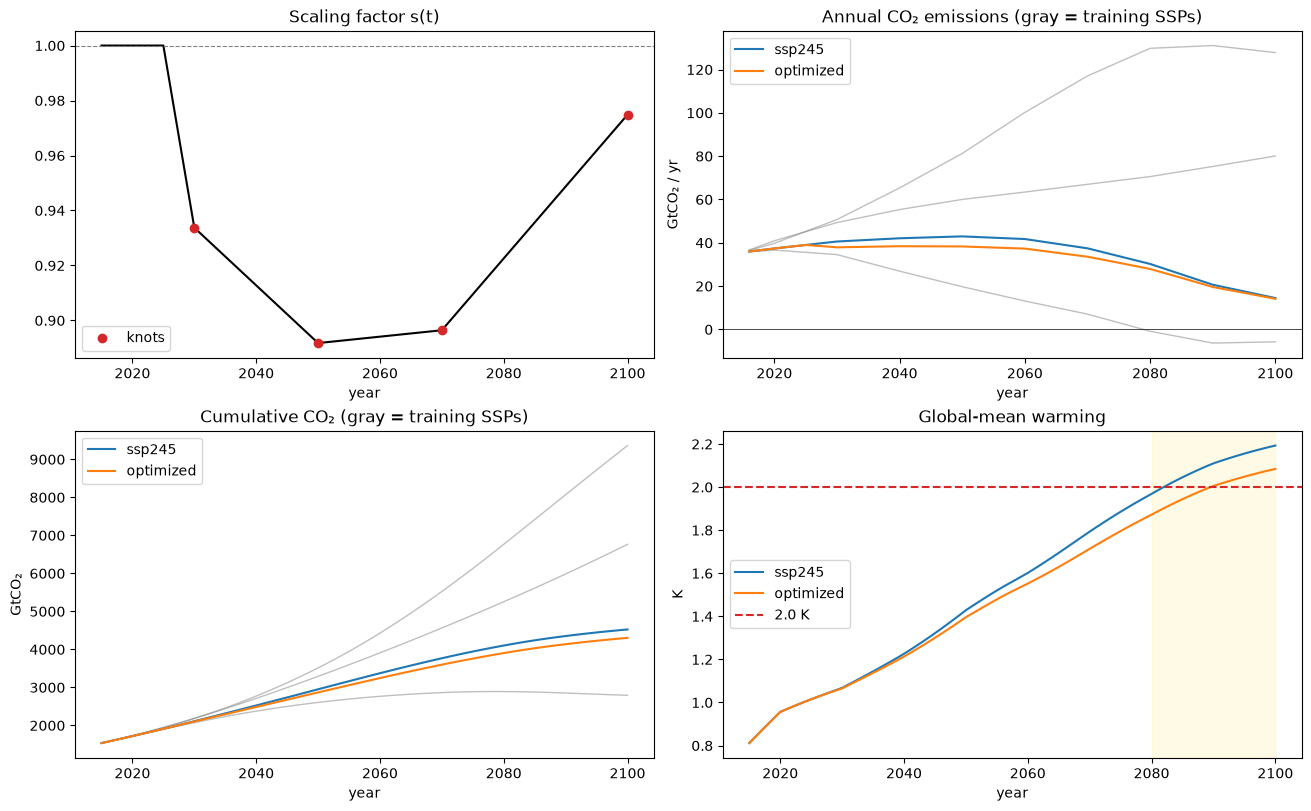

In [20]:
T_base_series = warming(jnp.ones(4))
emis_opt      = jnp.diff(co2_opt, prepend=co2_opt[0])
future_train  = [s for s in TRAIN if s.startswith("ssp")]       # ssp126, ssp370, ssp585

fig, ax = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)

# (a) scaling factor
ax[0, 0].plot(years, scale(p_opt), color="k")
ax[0, 0].scatter(KNOT_YEARS[1:], p_opt, color="tab:red", zorder=3, label="knots")
ax[0, 0].axhline(1, ls="--", color="gray", lw=0.8)
ax[0, 0].set(title="Scaling factor s(t)", xlabel="year"); ax[0, 0].legend()

# (b) annual emissions
for s in future_train:
    c = data[s]["co2"]
    ax[0, 1].plot(data[s]["years"][1:], np.diff(c), color="gray", alpha=0.5, lw=1)
ax[0, 1].plot(years[1:], emis_base[1:], label="ssp245")
ax[0, 1].plot(years[1:], emis_opt[1:],  label="optimized")
ax[0, 1].axhline(0, color="k", lw=0.5)
ax[0, 1].set(title="Annual CO₂ emissions (gray = training SSPs)",
             xlabel="year", ylabel="GtCO₂ / yr"); ax[0, 1].legend()

# (c) cumulative CO2
for s in future_train:
    ax[1, 0].plot(data[s]["years"], data[s]["co2"], color="gray", alpha=0.5, lw=1)
ax[1, 0].plot(years, co2_base, label="ssp245")
ax[1, 0].plot(years, co2_opt,  label="optimized")
ax[1, 0].set(title="Cumulative CO₂ (gray = training SSPs)",
             xlabel="year", ylabel="GtCO₂"); ax[1, 0].legend()

# (d) global-mean warming
ax[1, 1].plot(years, T_base_series, label="ssp245")
ax[1, 1].plot(years, T_opt,         label="optimized")
ax[1, 1].axhline(TARGET, ls="--", color="tab:red", label=f"{TARGET} K")
ax[1, 1].axvspan(START, END, color="gold", alpha=0.1)
ax[1, 1].set(title="Global-mean warming", xlabel="year", ylabel="K"); ax[1, 1].legend()

plt.savefig(f"{OUT}/fig4_inverse_pathway.png", dpi=150, bbox_inches="tight")
plt.show()

Years with cumulative CO₂ outside the training envelope: []


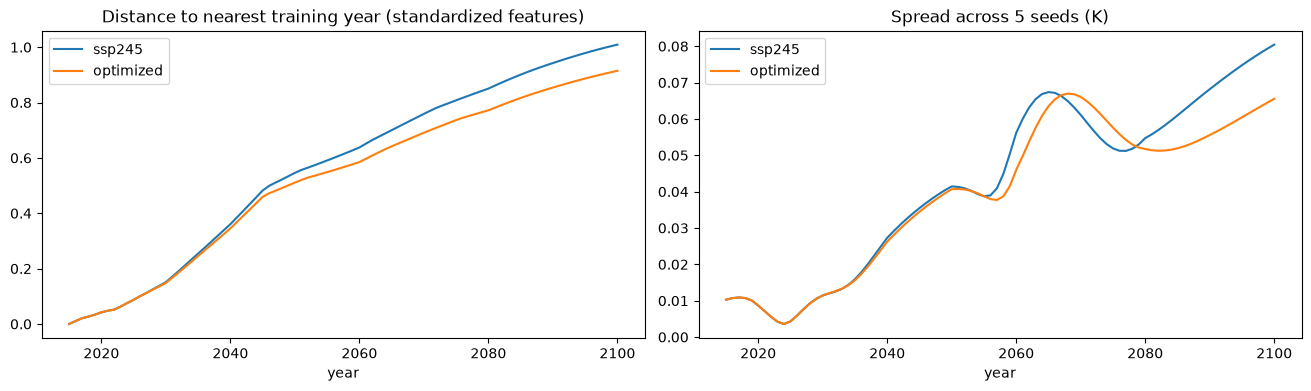

In [21]:
# ── Check 1: CO2 outside the per-year envelope of training SSPs? ─────────────
env = np.stack([data[s]["co2"] for s in future_train])           # same 2015–2100 years
lo, hi = env.min(0), env.max(0)
out = (np.asarray(co2_opt) < lo) | (np.asarray(co2_opt) > hi)
print("Years with cumulative CO₂ outside the training envelope:", years[out])

# ── Check 2: distance in the standardized 12-feature space ──────────────────
def std_feats(co2):
    f = features(co2, ch4, so2, bc, PRE_FROZEN)
    return np.asarray((f - PRE_FROZEN["f_mean"]) / PRE_FROZEN["f_std"])

F_tr = (F_train - np.asarray(PRE_FROZEN["f_mean"])) / np.asarray(PRE_FROZEN["f_std"])
def nn_dist(F):
    return np.sqrt(((F[:, None, :] - F_tr[None]) ** 2).sum(-1)).min(1)

d_base, d_opt = nn_dist(std_feats(co2_base)), nn_dist(std_feats(co2_opt))

# ── Check 3: do the 5 seeds disagree more on the optimized path? ────────────
def seed_spread(co2):
    per_seed = jax.vmap(lambda prm: gmean(predict(prm, co2, ch4, so2, bc, PRE_FROZEN)))(STACKED)
    return np.asarray(per_seed.std(0))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), constrained_layout=True)
ax[0].plot(years, d_base, label="ssp245"); ax[0].plot(years, d_opt, label="optimized")
ax[0].set(title="Distance to nearest training year (standardized features)", xlabel="year")
ax[0].legend()
ax[1].plot(years, seed_spread(co2_base), label="ssp245")
ax[1].plot(years, seed_spread(co2_opt),  label="optimized")
ax[1].set(title="Spread across 5 seeds (K)", xlabel="year"); ax[1].legend()
plt.savefig(f"{OUT}/fig4_extrapolation_checks.png", dpi=150, bbox_inches="tight")
plt.show()